# 14 — Comparativa de todos los detectores

Este notebook pone **en una sola comparación** todos los detectores de régimen (calma / crisis) del proyecto: los 12
del benchmark v2, las variantes de la Fase 2 con el pool de datos sin comprimir
([ADR-010](../../docs/decisions/ADR-010-preregistro-pool-crudo.md)), el menú de termómetros por bloque que se descartó
([ADR-009](../../docs/decisions/ADR-009-resultados-pool.md)) y los dos supervisados. No ajusta ningún modelo: solo lee
`results/` y dibuja.

**Cómo se mide.** Cada detector marca cada día como calma o crisis, siempre fuera de muestra (walk-forward causal). Se
compara con un catálogo fijo de crisis históricas `[pico, suelo]`:

- **recall por evento**: qué fracción de las crisis detecta (al menos 3 sesiones seguidas en crisis dentro de la
  ventana);
- **precisión diaria**: qué fracción de los días que marca como crisis caen dentro de una crisis;
- **score de detección** = F1 de las dos (0 = inútil, 1 = perfecto). Es el criterio del
  [ADR-003](../../docs/decisions/ADR-003-causalidad-calendario-estado-ranking.md).
- **MCS** (*model confidence set*, [ADR-008](../../docs/decisions/ADR-008-preregistro-pool-termometros.md) §4): el
  conjunto de detectores que los datos no permiten distinguir del mejor al 10 %. Es la prueba formal; el score es
  la descriptiva.

Las dos **pistas** no se mezclan nunca: **A** (1970–2026, 17 crisis evaluables, pocas series) y **B** (2010–2026, 9
crisis, muchas series).

**Todas las cifras salen de celdas**; el código está en `regimenes.benchmark.panorama` y las figuras se guardan en
`results/detectores/comparativa/`.

| § | contenido |
|---|---|
| 0 | resumen ejecutivo: una figura y cinco conclusiones |
| 1 | qué se compara: inventario de detectores, familias y menús |
| 2 | gate de comparabilidad y crisis evaluadas fuera de muestra |
| 3 | ranking principal v3 |
| 4 | recall por evento frente a precisión |
| 5 | detector × crisis |
| 6 | persistencia, estabilidad y coste |
| 7 | ¿sirve el pool? (sin comprimir: P y R; comprimido: menú T) |
| 8 | supervisados: el techo |
| 9 | robustez del criterio y limitaciones |
| 10 | conclusiones y qué pasa a las fusiones |

In [1]:
import warnings

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

from regimenes.benchmark import panorama as pn

V2, PROCEDENCIA = pn.cargar_v2()                 # 12 detectores de v2 (results/benchmark)
POOL = pn.cargar_pool()                          # 20 variantes de la Fase 2 (results/detectores/pool)
MENU_T = pn.cargar_menu_t()                      # 6 multivariantes con el menú T (results/detectores/menus)
MENUS = pn.menus_principales()                   # N y U, más P y R si el §5 del ADR-010 se cumple
R = pn.ranking_principal(MENUS['menus'], V2)     # ranking principal v3 (no supervisados)
TODAS = pn.metricas_todas(V2)                    # todos, con nivel y score del criterio
BASE = pn.baselines()                            # referencias triviales (vara del ADR-008)
TECHO = pn.tabla_techo()                         # supervisados frente al mejor no supervisado
TABLA_POOL = pn.tabla_pool(R)                    # criterio (a) y (b) del ADR-010 §5
TABLAS_T = pn.tablas_menu_t()                    # ablaciones del ADR-009
if MENUS['aviso']:
    print(MENUS['aviso'])
print(f"Menús del ranking principal: {', '.join(MENUS['menus'])} · filas: v2 {len(V2)}, pool {len(POOL)}, "
      f"menú T {len(MENU_T)} · figuras en {pn.pl.rel(pn.FIGURAS)}")

Menús del ranking principal: N, U, P, R · filas: v2 24, pool 20, menú T 12 · figuras en results/detectores/comparativa


## 0. Resumen ejecutivo

Cada punto es un detector (o una variante) en una pista, situado por su score de detección. Las filas agrupan lo que
se ha probado: el **núcleo** (menús N y U, el ranking de siempre), el **pool sin comprimir** (P y R, Fase 2), el
**menú T** (termómetros por bloque, descartado), los **supervisados** (que aprenden de las etiquetas de crisis) y las
**referencias triviales** (siempre crisis, azar, un umbral de volatilidad). Color = familia; forma = menú; hueco = no
pasa los filtros del criterio. La línea punteada marca al mejor del núcleo.

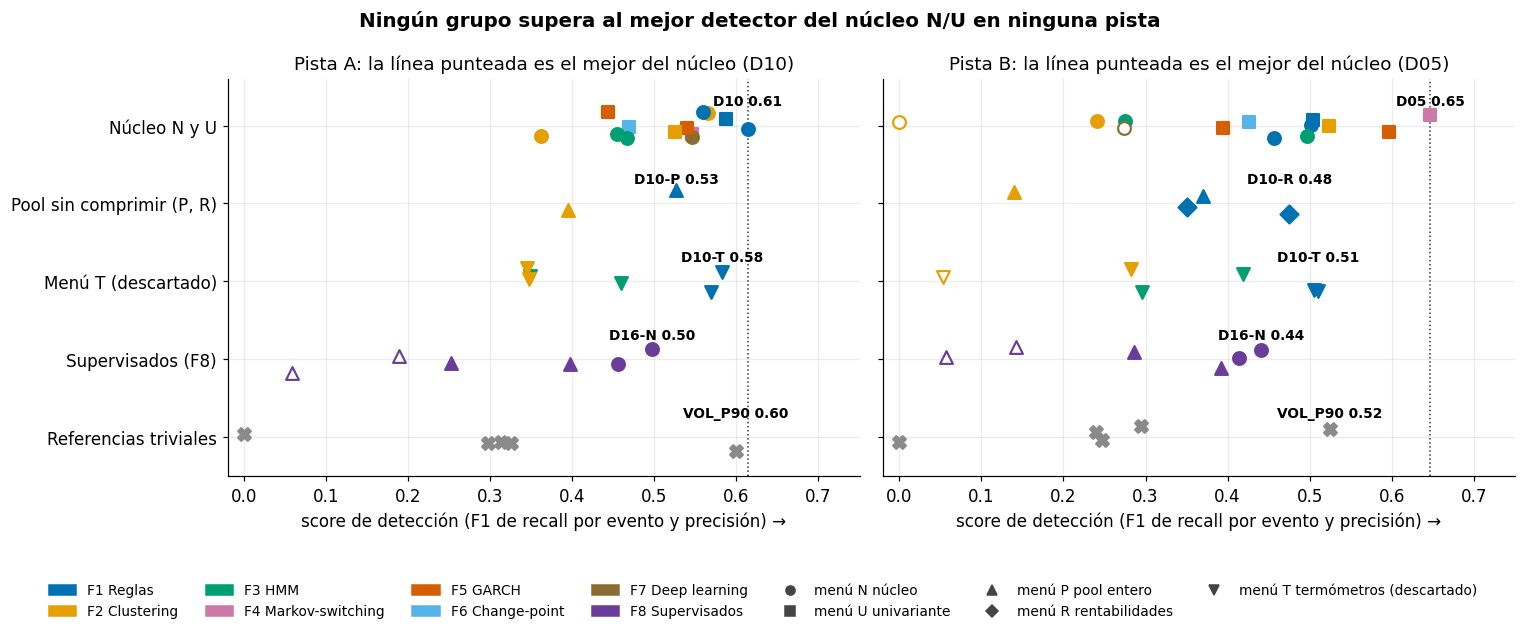

In [2]:
RESUMEN = pn.tabla_resumen(R, TODAS, BASE)
fig = pn.figura_resumen(RESUMEN)
pn.guardar(fig, '00_resumen')
plt.show()

In [3]:
HECHOS = pn.hechos(R, BASE, TABLA_POOL, MENUS['criterio'], TABLAS_T, TECHO)
display(Markdown('\n'.join(f'{i}. {c}' for i, c in enumerate(pn.conclusiones(HECHOS), 1))))

1. **El primero depende de la pista y del criterio.** Por score de detección encabeza D10 en A (0.614) y D05 en B (0.647); por pérdida del MCS el primero es D06 en A (0.550) y D05 en B (0.610). Todos son del núcleo N/U.
2. **Los datos no separan a la mayoría.** Dentro del MCS al 10 % quedan 13 de 15 detectores en A y 13 de 17 en B. La regla trivial `VOL_P90` (un umbral sobre la volatilidad) tiene score 0.600 en A — sería el puesto 2 — y queda dentro del MCS; en B queda fuera (score 0.525).
3. **El pool sin comprimir aporta solo en lo formal.** Veredicto del ADR-010 §5: «aporta» (cumplen (a) y (b): D18-P en A; D10-R, D18-P en B). Pero la mejor variante del pool queda 8.ª en A (D10-P, 0.527) y 7.ª en B (D10-R, 0.475): no desplaza a N.
4. **Comprimir el pool en termómetros (menú T) no sirve.** Con T mejoran 1 de 6 multivariantes en A y 5 de 6 en B; los bloques económicos quedan en el percentil 83 (A) y 93 (B) de 100 repartos al azar. Descartado (ADR-009).
5. **Ni con etiquetas se gana a lo simple.** Ningún supervisado mejora al mejor no supervisado: en A el mejor es D16-N (0.498 frente a 0.614 de D10) y en B D16-N (0.441 frente a 0.647 de D05). Con el pool P rinden peor que con N (D16: 0.19 frente a 0.50 en A; 0.14 frente a 0.44 en B).

## 1. Qué se compara

**Familias** (una por notebook, con la teoría y el diagnóstico de cada detector):

| familia | detectores | notebook |
|---|---|---|
| F1 Reglas / umbrales | D01 volatilidad o VIX, D02 riesgo compuesto, D10 turbulencia de Mahalanobis, D14 *absorption ratio* | [06](06_familia_F1_reglas.ipynb) |
| F2 Clustering y *jump models* | D03 GMM, D09 *jump model*, D15 *jump model* de Shu, D18 *sparse jump model* | [07](07_familia_F2_clustering.ipynb) |
| F3 HMM | D04 HMM gaussiano, D08 HMM t-Student | [08](08_familia_F3_hmm.ipynb) |
| F4 Markov-switching | D05 MS de varianza | [09](09_familia_F4_markov_switching.ipynb) |
| F5 GARCH | D06 GJR-GARCH-t, D11 MS-GARCH | [10](10_familia_F5_garch.ipynb) |
| F6 Change-point | D07 CUSUM online | [11](11_familia_F6_changepoint.ipynb) |
| F7 Deep learning | D12 autoencoder + GMM | [12](12_familia_F7_deep.ipynb) |
| F8 Supervisados (aparte) | D16 logit L1, D17 random forest | [13](13_familia_F8_supervisado.ipynb) |

**Menús** (qué datos ve cada detector; el sufijo del id lo indica):

| menú | datos | dónde |
|---|---|---|
| **N** núcleo | 4–5 series clave por pista | v2 (sin sufijo) |
| **U** univariante | una sola serie (rentabilidad o volatilidad del S&P 500, o VIX) | v2 y D15-U |
| **P** pool entero | todas las columnas del pool (35 en A, 77 en B) | Fase 2, ADR-010 |
| **R** rentabilidades | 22 rentabilidades multiactivo (solo B) | Fase 2, ADR-010 |
| **T** termómetros | una PC1 por bloque económico | ADR-008, **descartado** en el ADR-009 |

El **ranking principal** reúne a los no supervisados de N, U, P y R (P y R entran porque el criterio del ADR-010 §5 se
cumplió; la celda de §3 lo comprueba). T y los supervisados se comparan aparte (§7 y §8). La tabla siguiente es el
inventario completo, con el nivel del criterio (`elegible`, o el filtro que no pasa) y el score en cada pista.

In [4]:
INVENTARIO = pn.inventario(TODAS, R)
display(pn.resumen_inventario(INVENTARIO))
display(INVENTARIO.drop(columns='detector').set_index('id').round(3))

menu,N,U,P,R,T,ids
familia,,,,,,
F1 Reglas,2,1,1,2,2,"D01, D02, D02-T, D10, D10-P, D10-R, D10-T, D14-R"
F2 Clustering,2,1,1,0,2,"D03, D03-T, D09, D09-T, D15-U, D18-P"
F3 HMM,2,0,0,0,2,"D04, D04-T, D08, D08-T"
F4 Markov-switching,0,1,0,0,0,D05
F5 GARCH,0,2,0,0,0,"D06, D11"
F6 Change-point,0,1,0,0,0,D07
F7 Deep learning,1,0,0,0,0,D12
F8 Supervisados,2,0,4,0,0,"D16-N, D16-P, D16-P-excl, D17-N, D17-P, D17-P-..."


,familia,menu,supervisado,en_ranking_principal,nivel_A,score_A,nivel_B,score_B
id,,,,,,,,
D01,F1 Reglas,U,False,True,elegible,0.587,elegible,0.505
D02,F1 Reglas,N,False,True,elegible,0.559,elegible,0.501
D02-T,F1 Reglas,T,False,False,elegible,0.570,elegible,0.506
D10,F1 Reglas,N,False,True,elegible,0.614,elegible,0.457
D10-P,F1 Reglas,P,False,True,elegible,0.527,elegible,0.370
D10-R,F1 Reglas,R,False,True,,NaN,elegible,0.475
D10-T,F1 Reglas,T,False,False,elegible,0.582,elegible,0.510
D14-R,F1 Reglas,R,False,True,,NaN,elegible,0.350
D03,F2 Clustering,N,False,True,elegible,0.565,elegible,0.241


## 2. Gate de comparabilidad

Antes de ordenar nada se comprueba que dentro de cada pista **todos** (v2, pool y menú T) comparten inicio, fin y
longitud del periodo fuera de muestra (OOS) y ventana de entrenamiento, sin duplicados, y que las métricas de v2 son
trazables a la ejecución registrada en `manifest.json` (verificación local completa si los datos están en la
máquina; si no, solo la huella de cada CSV). Las distintas frecuencias de reajuste (21 sesiones en general; 63 en D05;
126 en D08 y D11) son configuración de cómputo, no ventanas de evaluación distintas.

In [5]:
GATE, COMPARABLE = pn.gate(V2, POOL, MENU_T)
display(pd.Series(PROCEDENCIA, name='procedencia v2').to_frame())
display(GATE)
print('Gate de comparabilidad:', 'OK' if COMPARABLE and PROCEDENCIA['trazable'] else 'FALLA')

,procedencia v2
verificacion_local,True
motivo,
manifest_utc,2026-09-29T12:41:35.741870+00:00
csv_con_huella_del_manifiesto,24/24
trazable,True


,filas,de_v2,duplicados,inicios_oos,finales_oos,longitudes_oos,train_configs,oos
pista,,,,,,,,
A,27,12,0,1,1,1,1,1970-05-12 → 2026-05-29 (n=14133)
B,29,12,0,1,1,1,1,2010-04-12 → 2026-05-29 (n=4059)


Gate de comparabilidad: OK


### 2.1 Qué crisis se evalúan realmente fuera de muestra

El catálogo asigna 18 crisis a la pista A y 10 a la B, pero el primer entrenamiento consume ocho años en A y tres en
B. Una crisis **fuera** del OOS no cuenta (ni premia ni penaliza); una **parcial** cuenta como un evento entero.

In [6]:
VENTANAS = pn.ventanas_crisis(V2)
display(VENTANAS.groupby(['pista', 'estado']).size().unstack(fill_value=0))
display(VENTANAS[VENTANAS.estado != 'completa'])
for t, p in VENTANAS[VENTANAS.estado != 'fuera'].groupby('pista'):
    corta, larga = p.loc[p.dias_oos_aprox.idxmin()], p.loc[p.dias_oos_aprox.idxmax()]
    print(f'Pista {t}: {len(p)} crisis evaluadas; la más corta {corta.crisis} (~{corta.dias_oos_aprox} sesiones), '
          f'la más larga {larga.crisis} (~{larga.dias_oos_aprox}).')

estado,completa,fuera,parcial
pista,,,
A,16,1,1
B,9,1,0


,pista,crisis,pico,suelo,dias_oos_aprox,estado
0,A,credit_crunch_1966,1966-02-09,1966-10-07,0,fuera
1,A,bear_1969_70,1968-11-29,1970-05-26,11,parcial
18,B,gfc_2007_09,2007-10-09,2009-03-09,0,fuera


Pista A: 17 crisis evaluadas; la más corta volmageddon_2018q1 (~10 sesiones), la más larga dotcom_2000_02 (~664).
Pista B: 9 crisis evaluadas; la más corta volmageddon_2018q1 (~10 sesiones), la más larga inflation_bear_2022 (~203).


Los episodios son muy desiguales: por eso el recall cuenta **eventos** (una crisis de diez sesiones pesa lo mismo
que una de seiscientas) y los días solo entran en la precisión.

## 3. Ranking principal v3

**Criterio** (ADR-003). Primero un **nivel** y, dentro de él, el score; los empates los rompe la persistencia:

| nivel | condición | lectura |
|---|---|---|
| `elegible` | pasa los filtros | compite por score |
| `precision_no_supera_azar` | precisión ≤ tasa base (lo que acierta marcar crisis siempre) | sus alarmas no se concentran en crisis |
| `parpadeo` | régimen medio < 5 sesiones o episodio de crisis medio < 3 | cambia de estado sin sentido |
| `degenerado` | salida constante o nunca marca crisis | no es un detector |

Parámetros fijos y registrados: racha mínima 3 sesiones, β = 1, lift > 1, filtros 5 y 3 sesiones. El §9 mide cuánto
mueven el orden. Justificación del criterio: F-score compuesto de Garg et al. (2021), racha mínima frente al
*point-adjust* (Kim et al., 2022) y comparación con señales triviales de la literatura de alertas tempranas
(Kaminsky et al., 1998; Sarlin, 2013); detalle en el ADR-003.

**Menús.** El ranking v3 deja el menú T (desviación declarada del ADR-008 §4, ADR-009 §6) y pasa al núcleo N con los
univariantes en U. P y R entran solo si el ADR-010 §5 dice que el pool sin comprimir aporta en las dos pistas.

**Cómo leer la figura.** Barras = score, color = familia, rayado = variante del pool. ● = dentro del MCS al 10 %,
○ = fuera. Las líneas verticales son referencias triviales: `VOL_P90` marca crisis cuando la volatilidad supera su
percentil 90 histórico; `SIEMPRE_CRISIS` y `AZAR_PERSISTENTE` no saben nada de las crisis.

ADR-010 §5 cumplido en las dos pistas: True → menús N, U, P, R


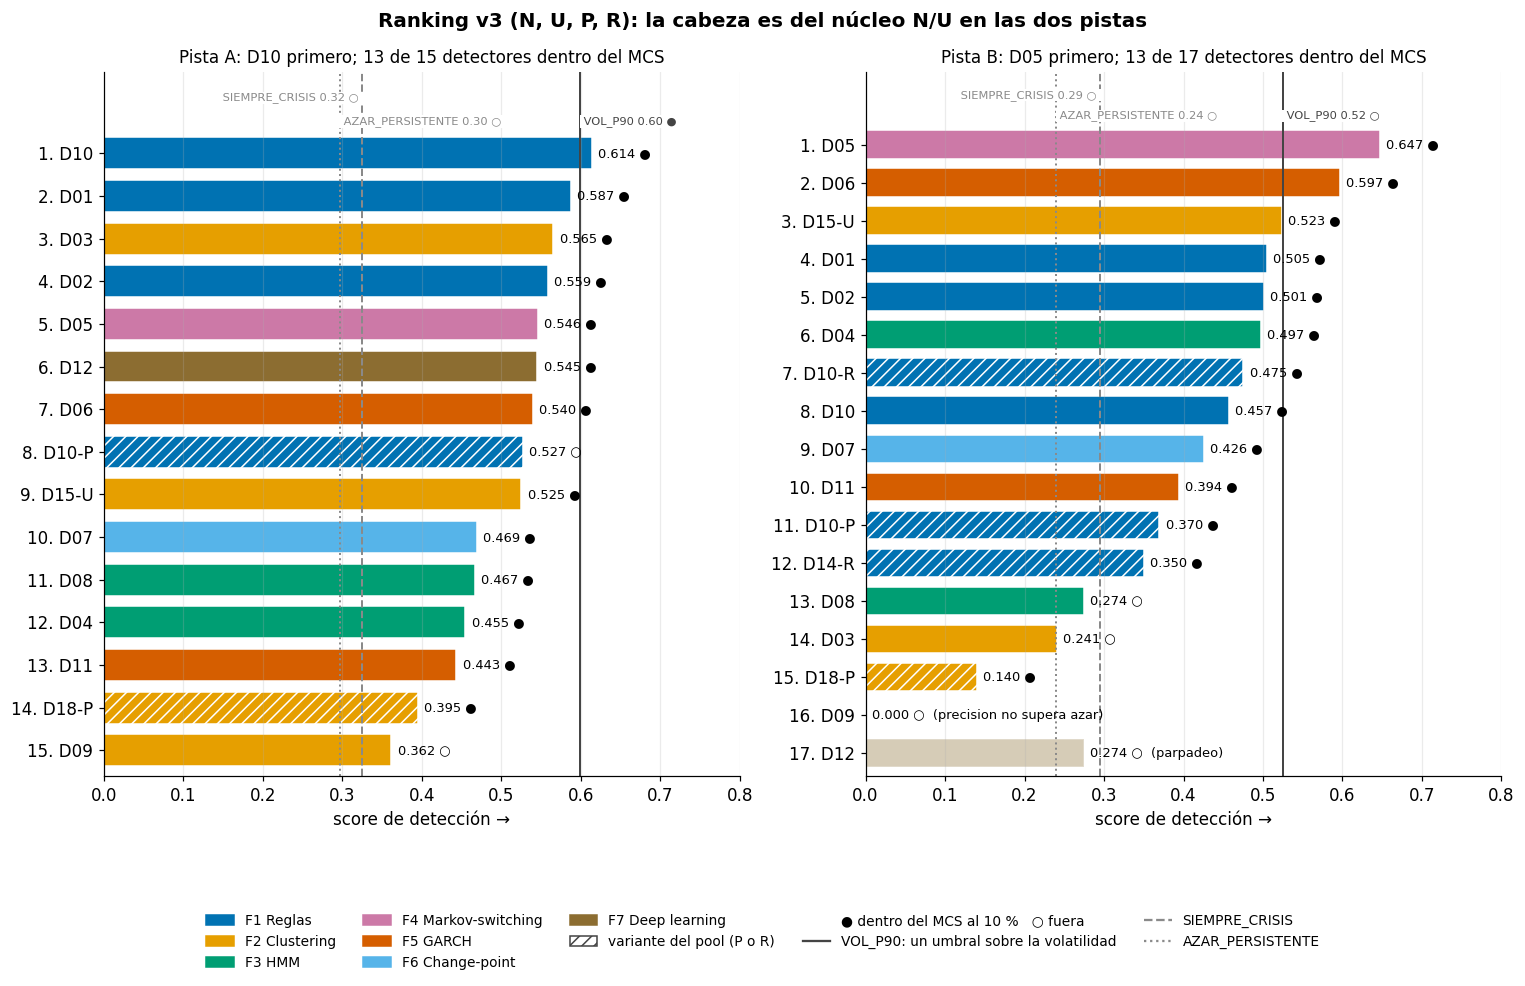

id menu familia_tfm            nivel_etiqueta  score_deteccion  det_event_recall  det_n_detectados  det_n_eventos  det_precision  det_lift_precision  en_mcs  perdida_mcs
pista puesto_deteccion                                                                                                                                                                              
A     1                   D10    N          F1                  elegible            0.614             0.941                16             17          0.455               2.347    True        0.652
      2                   D01    U          F1                  elegible            0.587             0.941                16             17          0.427               2.200    True        0.607
      3                   D03    N          F2                  elegible            0.565             0.882                15             17          0.416               2.144    True        0.689
      4                   D02    N          F1                  elegible            0.559             0.706                12             17          0.462               2.384    True        0.719
      5                   D05    U          F4                  elegible            0.546             1.000                17             17          0.375               1.936    True        0.565
      6                   D12    N          F7                  elegible            0.545             0.882                15             17          0.395               2.035    True        0.653
      7                   D06    U          F5                  elegible            0.540             1.000                17             17          0.370               1.906    True        0.550
      8                 D10-P    P          F1                  elegible            0.527             0.588                10             17          0.477               2.459   False        0.820
      9                 D15-U    U          F2                  elegible            0.525             0.765                13             17          0.400               2.063    True        0.717
      10                  D07    U          F6                  elegible            0.469             0.824                14             17          0.328               1.692    True        0.762
      11                  D08    N          F3                  elegible            0.467             0.824                14             17          0.326               1.681    True        0.758
      12                  D04    N          F3                  elegible            0.455             1.000                17             17          0.294               1.518    True        0.703
      13                  D11    U          F5                  elegible            0.443             0.765                13             17          0.312               1.610    True        0.824
      14                D18-P    P          F2                  elegible            0.395             0.824                14             17          0.259               1.338    True        0.761
      15                  D09    N          F2                  elegible            0.362             0.471                 8             17          0.294               1.514   False        0.975
B     1                   D05    U          F4                  elegible            0.647             1.000                 9              9          0.478               2.767    True        0.610
      2                   D06    U          F5                  elegible            0.597             0.889                 8              9          0.449               2.602    True        0.621
      3                 D15-U    U          F2                  elegible            0.523             0.778                 7              9          0.394               2.283    True        0.756
      4                   D01    U          F1                  elegible            0.5

In [7]:
print(f"ADR-010 §5 cumplido en las dos pistas: {MENUS['aporta']} → menús {', '.join(MENUS['menus'])}")
fig = pn.figura_ranking(R, BASE)
pn.guardar(fig, '03_ranking_v3')
plt.show()
display(R[pn.COLUMNAS_RANKING].set_index(['pista', 'puesto_deteccion']).round(3))

In [8]:
# ranking_v2.csv: el ranking ADR-003 de los 12 de v2 (con columnas legacy). Lo leen los notebooks de familia.
ruta, cambiado = pn.exportar_ranking_v2(V2)
print(f"{pn.pl.rel(ruta)} {'actualizado' if cambiado else 'sin cambios'}")
display(pn.baselines_frente(R, BASE).set_index(['pista', 'referencia']).round(3))

results/benchmark/ranking_v2.csv sin cambios


score en_mcs  detectores_por_debajo  de                                             cuales
pista referencia                                                                                                  
A     SIEMPRE_CRISIS    0.325      ○                      0  15                                                   
      SIEMPRE_CALMA     0.000      ○                      0  15                                                   
      AZAR_IID          0.313      ○                      0  15                                                   
      AZAR_PERSISTENTE  0.297      ○                      0  15                                                   
      VOL_P90           0.600      ●                     14  15  D01, D03, D02, D05, D12, D06, D10-P, D15-U, D0...
B     SIEMPRE_CRISIS    0.295      ○                      5  17                          D08, D03, D18-P, D09, D12
      SIEMPRE_CALMA     0.000      ○                      0  17                                                   
      AZAR_IID          0.247      ○                      3  17                                    D03, D18-P, D09
      AZAR_PERSISTENTE  0.240      ○                      2  17                                         D18-P, D09
      VOL_P90           0.525      ○                     15  17  D15-U, D01, D02, D04, D10-R, D10, D07, D11, D1...

**Lectura.** La regla trivial `VOL_P90` es la referencia exigente: en A puntúa casi como el primero y el MCS no la
separa de los mejores; en B queda fuera del MCS. Las referencias sin información (`SIEMPRE_*`, `AZAR_*`) no
pasan los filtros del criterio (salida degenerada, parpadeo o precisión no mejor que la tasa base; tabla del §9),
así que quedan siempre por debajo de los elegibles; aun así, en score puro `SIEMPRE_CRISIS` supera en B a algunos detectores reales (la tabla los lista):
son detectores que apenas aportan sobre marcar crisis todos los días.

## 4. Recall por evento frente a precisión

Vista complementaria al score, sin imponer β. Arriba a la derecha es mejor; la línea roja es la frontera de Pareto
del ranking principal (nadie la mejora en los dos ejes a la vez). La línea vertical es la tasa base: a su izquierda,
la precisión no mejora al azar. Las curvas grises unen puntos con el mismo score. El menú T y los supervisados se
dibujan en hueco para ver dónde caerían.

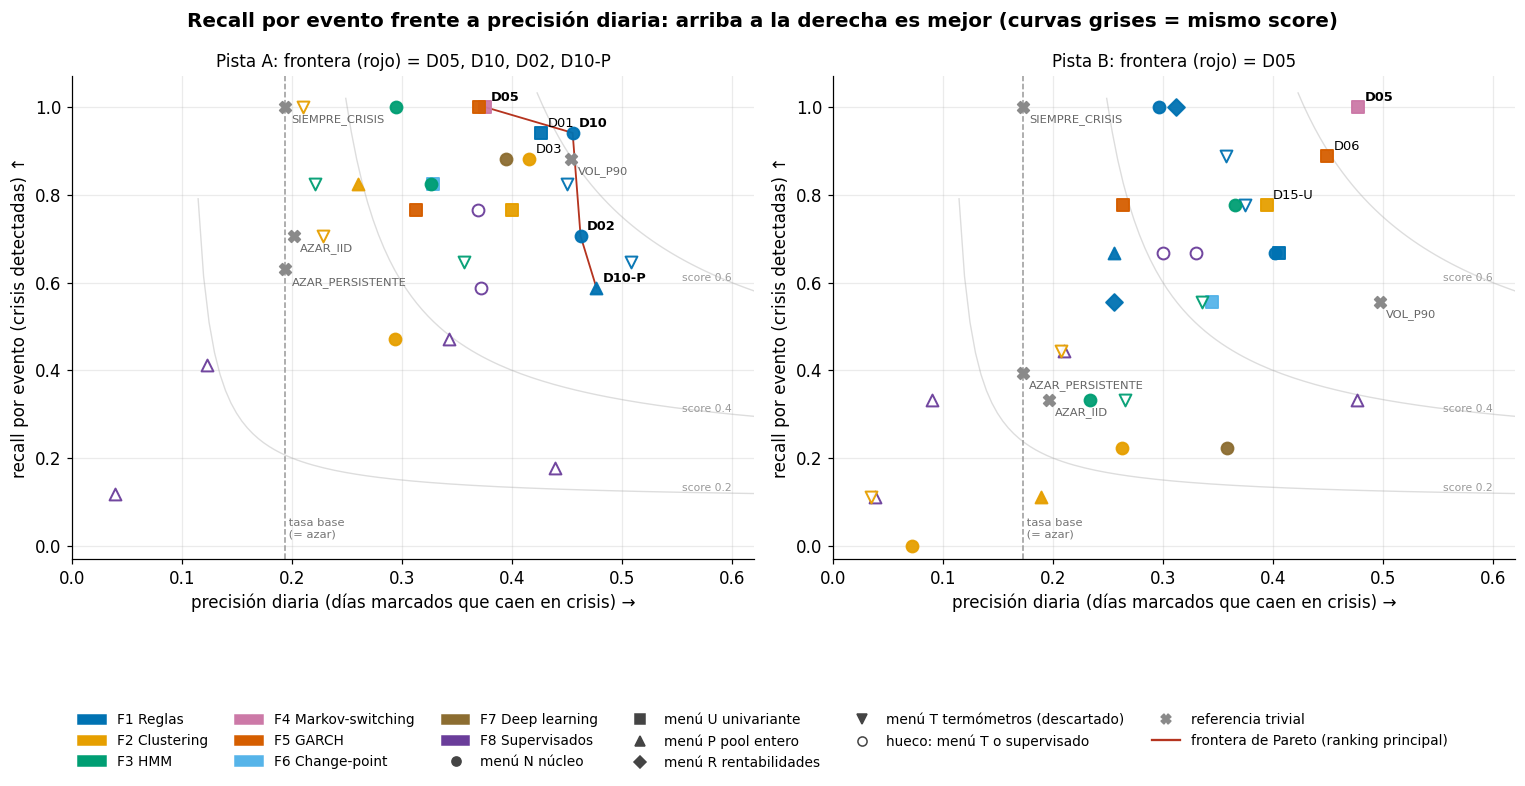

Pista A: tasa base 0.194; recall ≥ 0,8 en 10 de 15; precisión máxima 0.477 (D10-P); frontera: D05, D10, D02, D10-P
Pista B: tasa base 0.173; recall ≥ 0,8 en 4 de 17; precisión máxima 0.478 (D05); frontera: D05


In [9]:
fig = pn.figura_frontera(TODAS, R, BASE)
pn.guardar(fig, '04_recall_precision')
plt.show()
for t in pn.PISTAS:
    p = R[R.pista == t]
    print(f"Pista {t}: tasa base {p.det_base_rate.iloc[0]:.3f}; recall ≥ 0,8 en {int((p.det_event_recall >= .8).sum())} "
          f"de {len(p)}; precisión máxima {p.det_precision.max():.3f} ({p.loc[p.det_precision.idxmax(), 'id']}); "
          f"frontera: {', '.join(fig.fronteras[t])}")

**Lectura.** El recall por evento satura con facilidad en A (casi todos ven la mayoría de crisis) y la precisión es
lo que más discrimina. En B hay más dispersión en los dos ejes.

## 5. Detector × crisis

Color = qué fracción de los días de la crisis marca el detector (cobertura); ✓ = la detecta según el criterio.
Filas en el orden del ranking principal; entre paréntesis, cuántos detectores detectan cada crisis.

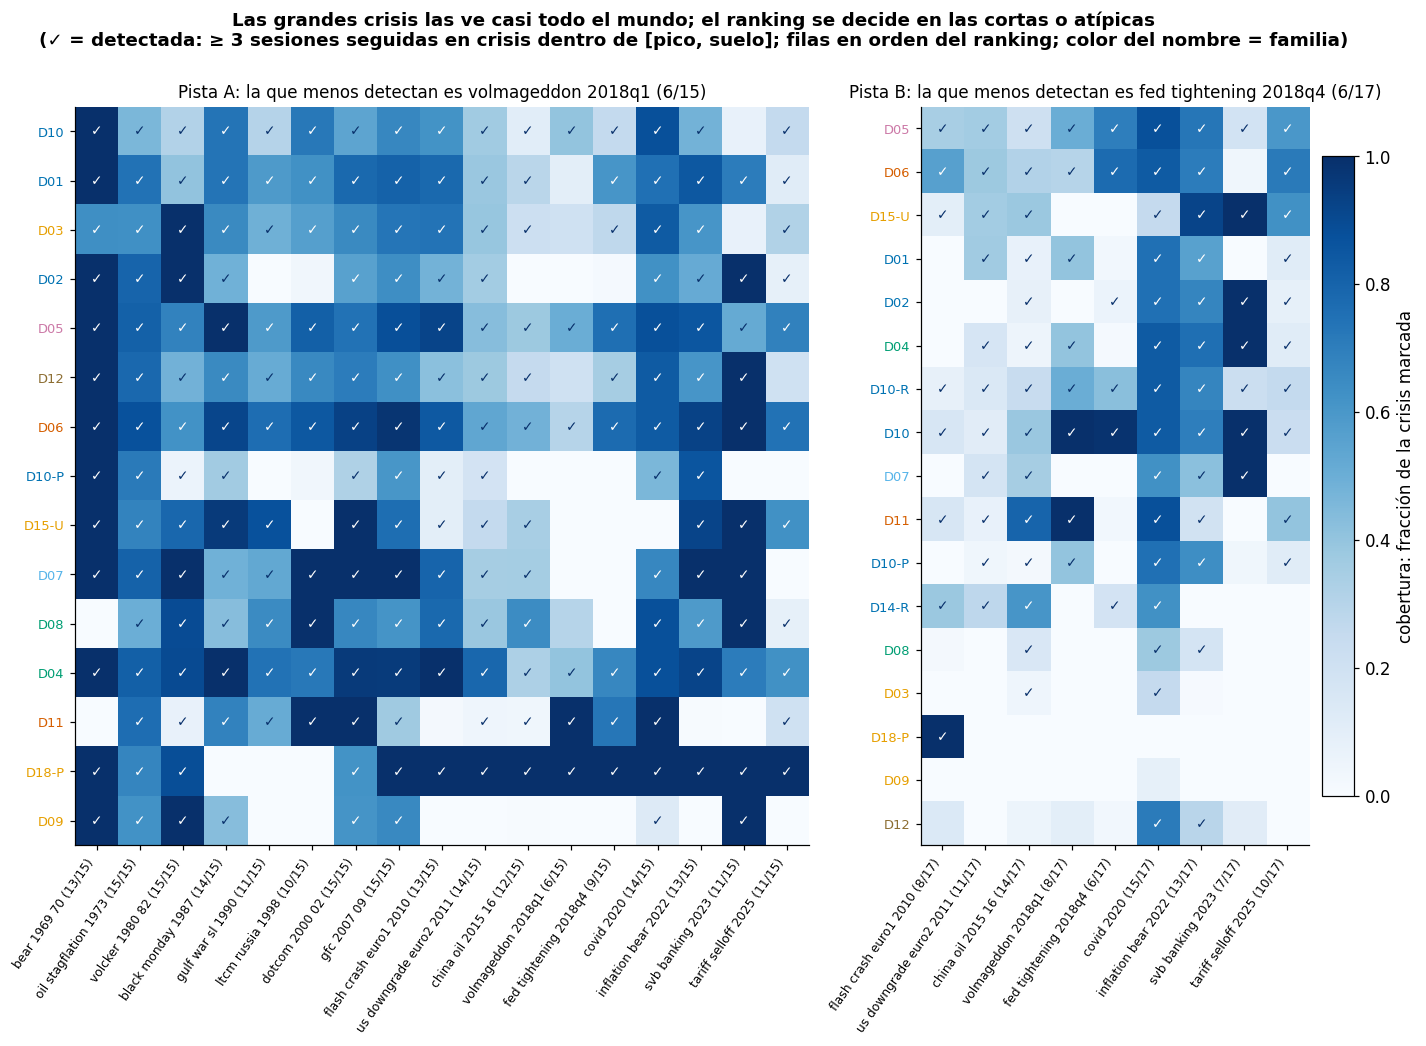

Pista A: menos detectadas → volmageddon_2018q1 (6/15), fed_tightening_2018q4 (9/15), ltcm_russia_1998 (10/15); detectadas por todos: gfc_2007_09, oil_stagflation_1973, dotcom_2000_02, volcker_1980_82
Pista B: menos detectadas → fed_tightening_2018q4 (6/17), svb_banking_2023 (7/17), flash_crash_euro1_2010 (8/17); detectadas por todos: ninguna


In [10]:
fig = pn.figura_crisis(R)
pn.guardar(fig, '05_detector_crisis')
plt.show()
for t in pn.PISTAS:
    det, cov = pn.matriz_crisis(R, t)
    frac = (det.sum() / det.notna().sum()).sort_values()
    print(f"Pista {t}: menos detectadas → " + ', '.join(f"{c} ({int(det[c].sum())}/{int(det[c].notna().sum())})"
                                                      for c in frac.index[:3])
          + f"; detectadas por todos: {', '.join(frac.index[frac == 1]) or 'ninguna'}")

**Lectura.** Las grandes crisis (la GFC en A, la COVID en las dos) las ve casi cualquier familia; el ranking se decide en los episodios
cortos o atípicos que la salida lista. Las variantes del pool se distinguen por su patrón: D18-P en A marca casi
todas las crisis recientes con cobertura alta (detecta mucho y marca demasiado) y en B solo detecta una.

## 6. Persistencia, estabilidad y coste

La persistencia no entra en el score: solo filtra el parpadeo y desempata. Aquí se ve contra el coste real del
walk-forward. `label_stability` tiene suelo 0,5 y depende de la frecuencia de reajuste.

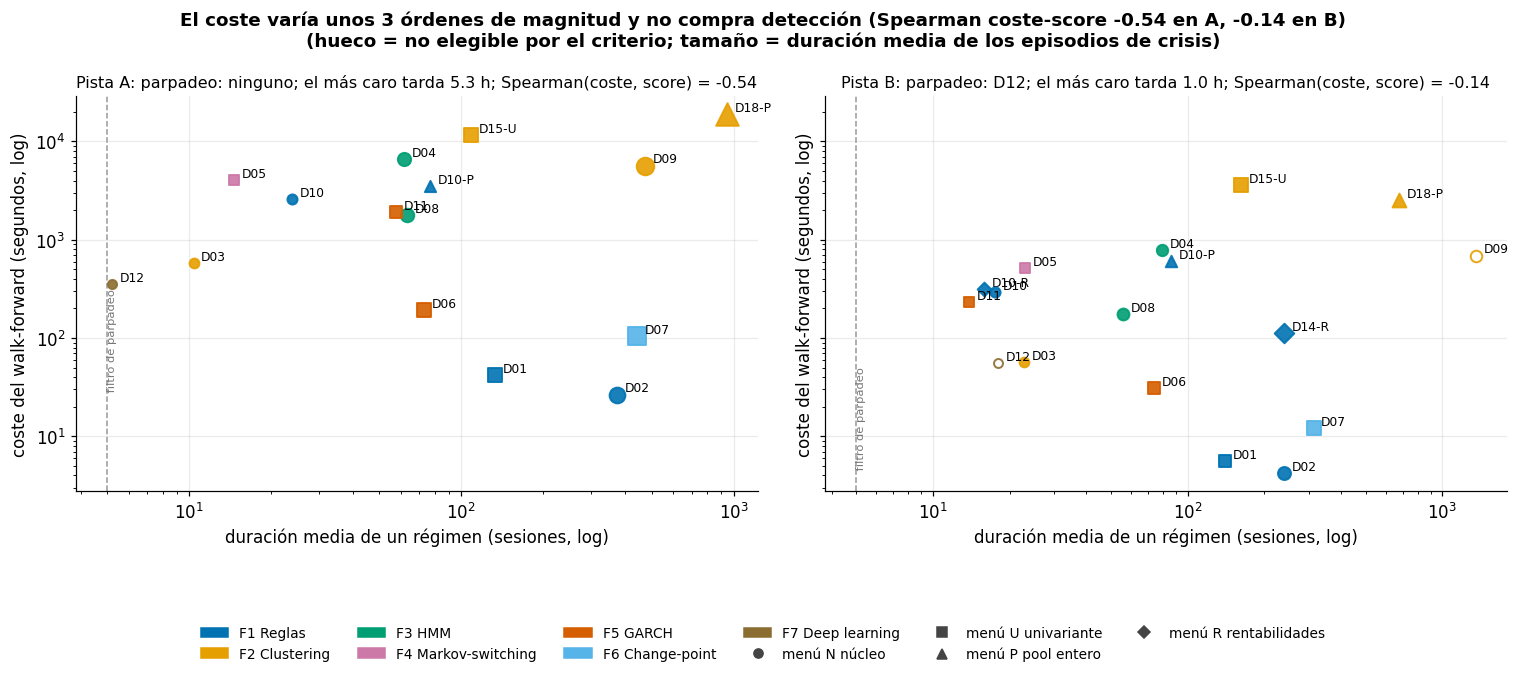

id menu            nivel_etiqueta  mean_regime_duration  det_mean_crisis_run  switching_rate  label_stability  coste_min
pista puesto_deteccion                                                                                                                             
A     1                   D10    N                  elegible                23.954                9.383           0.042            0.999     43.538
      2                   D01    U                  elegible               133.330               79.019           0.007            1.000      0.695
      3                   D03    N                  elegible                10.384                7.549           0.096            0.983      9.642
      4                   D02    N                  elegible               371.921              184.263           0.003            0.998      0.443
      5                   D05    U                  elegible                14.630               11.172           0.068            0.995     67.745
      6                   D12    N                  elegible                 5.231                3.080           0.191            0.995      5.860
      7                   D06    U                  elegible                72.851               62.598           0.014            0.998      3.180
      8                 D10-P    P                  elegible                76.810               22.772           0.013            0.998     57.936
      9                 D15-U    U                  elegible               108.715               77.108           0.009            0.969    194.162
      10                  D07    U                  elegible               441.656              432.500           0.002            1.000      1.758
      11                  D08    N                  elegible                63.377               78.716           0.016            0.773     29.600
      12                  D04    N                  elegible                61.448               68.965           0.016            0.979    109.367
      13                  D11    U                  elegible                57.686               35.484           0.017            0.897     31.522
      14                D18-P    P                  elegible               942.200             1030.375           0.001            0.996    316.007
      15                  D09    N                  elegible               471.100              318.400           0.002            0.988     94.601
B     1                   D05    U                  elegible                22.932                7.966           0.043            0.997      8.545
      2                   D06    U                  elegible                73.800               30.000           0.013            0.999      0.519
      3                 D15-U    U                  elegible               162.360               73.750           0.006            0.987     60.530
      4                   D01    U                  elegible               139.966               33.429           0.007            1.000      0.093
      5                   D02    N                  elegible               238.765               61.625           0.004            0.998      0.071
      6                   D04    N                  elegible                79.588               25.280           0.012            0.966     13.024
      7                 D10-R    R                  elegible                15.855                6.594           0.063            0.998      5.215
      8                   D10    N                  elegible                17.571               10.513           0.057            0.996      4.857
      9                   D07    U                  elegible               312.231              100.000           0.003            0.995      0.201
      10                  D11    U                  elegible                13.853                6.438           0.072            0.872      3.893
      11                D10-P  

In [11]:
fig = pn.figura_estabilidad(R)
pn.guardar(fig, '06_estabilidad_coste')
plt.show()
display(pn.tabla_estabilidad(R).set_index(['pista', 'puesto_deteccion']).round(3))

## 7. ¿Sirve el pool?

El pool son todas las series que se recogieron para el proyecto. Se probó de dos formas.

### 7.1 Sin comprimir: menús P y R (ADR-010)

Criterio pre-registrado (§5): el pool aporta si, **en cada pista**, alguna variante de P o R (a) mejora el score de
su par en N (D10-P y D10-R frente a D10, D14-R frente a D10, D18-P frente a D09) y (b) entra en el MCS al 10 % de
todos los no supervisados con los baselines. D15-U frente a D09 se reporta sin peso. En la figura, cada flecha va del
par en N a la variante; verde si mejora, rojo si empeora; la variante rellena si entra en el MCS.

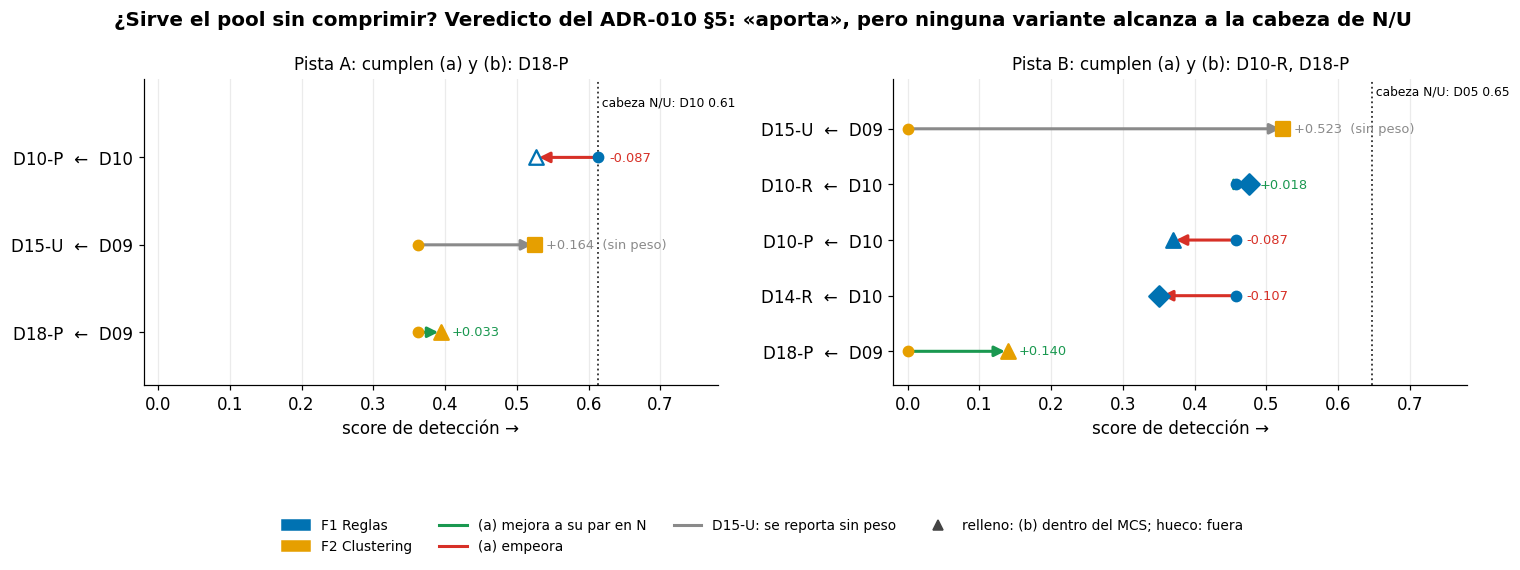

menu par_v2  score  score_par  delta_score  a_mejora_par  cuenta_para_veredicto  b_en_mcs  puesto_v3  cumple_a_y_b
pista id                                                                                                                      
A     D10-P    P    D10  0.527      0.614       -0.087         False                   True     False          8         False
      D15-U    U    D09  0.525      0.362        0.164          True                  False      True          9         False
      D18-P    P    D09  0.395      0.362        0.033          True                   True      True         14          True
B     D10-P    P    D10  0.370      0.457       -0.087         False                   True      True         11         False
      D10-R    R    D10  0.475      0.457        0.018          True                   True      True          7          True
      D14-R    R    D10  0.350      0.457       -0.107         False                   True      True         12         False
      D15-U    U    D09  0.523      0.000        0.523          True                  False      True          3         False
      D18-P    P    D09  0.140      0.000        0.140          True                   True      True         15          True

,candidatas,a_mejoran_par,b_en_mcs,cumplen_a_y_b,cumple_pista,vol_p90_fuera_del_mcs,veredicto
pista,,,,,,,
A,D10-P|D18-P,D18-P,D18-P,D18-P,True,False,aporta
B,D10-P|D10-R|D14-R|D18-P,D10-R|D18-P,D10-R|D14-R|D10-P|D18-P,D10-R|D18-P,True,True,aporta


In [12]:
fig = pn.figura_pool(TABLA_POOL, R, MENUS['criterio'])
pn.guardar(fig, '07_pool_sin_comprimir')
plt.show()
display(TABLA_POOL.set_index(['pista', 'id']).round(3))
display(MENUS['criterio'].set_index('pista')[['candidatas', 'a_mejoran_par', 'b_en_mcs', 'cumplen_a_y_b',
                                             'cumple_pista', 'vol_p90_fuera_del_mcs', 'veredicto']])

**Lectura.** Se cumple en las dos pistas, así que P y R entran en el ranking principal. Pero el aporte es formal y
estrecho: el par de D18-P (D09) es el detector de menor score de las dos pistas, la única comparación de par fuerte
(D10-R frente a D10, en B) gana por poco, y ninguna variante alcanza a la cabeza del núcleo.

### 7.2 Comprimido: menú T (ADR-008 y ADR-009, descartado)

Antes se probó a comprimir el pool en un «termómetro» por bloque económico (la primera componente principal de cada
bloque). Cuatro pruebas en una figura: ① cada multivariante con N y con T; ② la agrupación económica frente a 100
repartos de columnas al azar (criterio (b) del ADR-008); ③ media simple frente a PCA; ④ quitar un bloque cada vez.

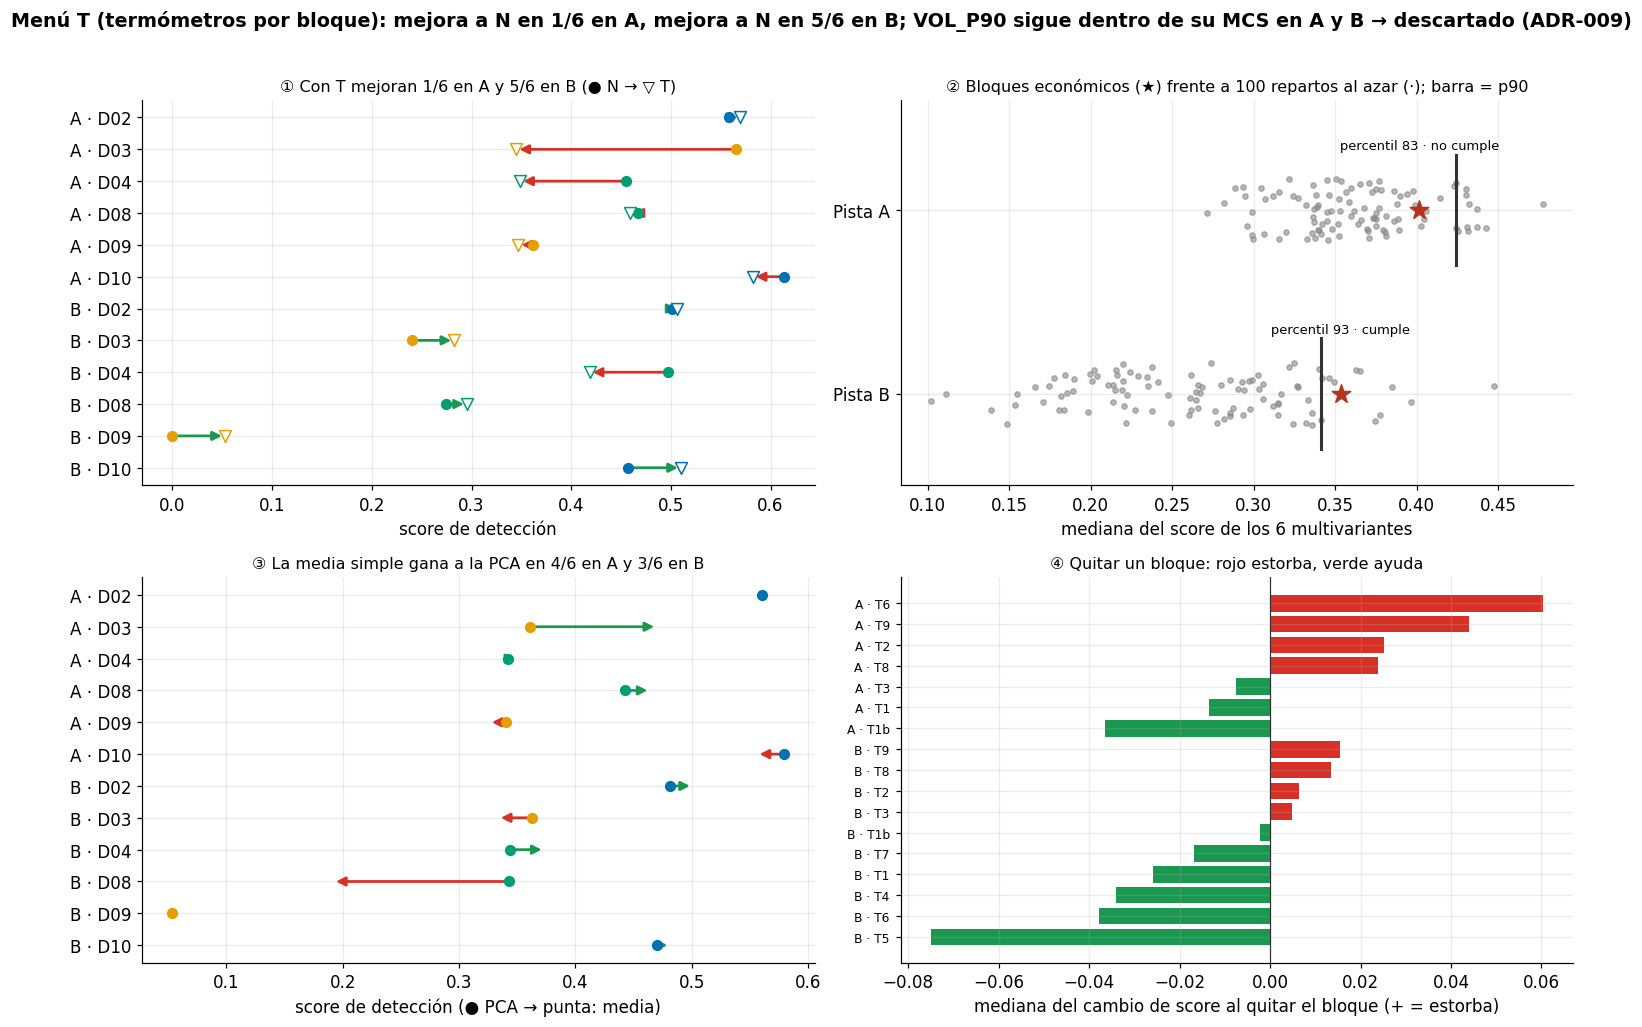

,n_comparados,n_mejoran_T,a_mayoria_mejora,mcs_miembros,c_algun_T_en_mcs,T_en_mcs,b_bloques_frente_a_azar
pista,,,,,,,
A,6,1,False,D06|D05|D01|D10|D12|D03|D04|D02|D08|D07|D11,False,NaN,"pendiente (Fase 2, 2.5)"
B,6,5,True,D05|D06|D10|D02_T|D04|D10_T|D11|D02|D07|D01|D0...,True,D02_T|D10_T|D04_T|D08_T,"pendiente (Fase 2, 2.5)"


,mediana_ref_t,p90_azar,percentil_ref_t,veredicto_b
pista,,,,
A,0.402,0.424,83.0,no cumple
B,0.354,0.341,93.0,cumple


In [13]:
fig = pn.figura_menu_t(TABLAS_T)
pn.guardar(fig, '07_menu_t')
plt.show()
display(TABLAS_T['criterios_adr008'].set_index('pista'))
display(TABLAS_T['criterio_b'].set_index('pista')[['mediana_ref_t', 'p90_azar', 'percentil_ref_t', 'veredicto_b']].round(3))

**Lectura.** En A el menú T empeora a 5 de los 6 multivariantes y no supera a repartir las columnas al azar. En B
mejora a 5 de 6 y supera al azar por poco, pero su MCS no deja fuera a `VOL_P90`. La media simple no pierde frente a
la PCA. Decisión del ADR-009 §6: **descartar el menú T**; el núcleo es N con U.

## 8. Supervisados: el techo

D16 y D17 aprenden de las etiquetas de crisis (solo las ya terminadas en cada reajuste, sin fuga). Por eso no
compiten en el ranking principal: responden si, **con** etiquetas, se puede superar al mejor no supervisado. `-excl`
saca del ajuste los días de crisis aún sin terminar (sensibilidad). ● = dentro del MCS conjunto con los no
supervisados.

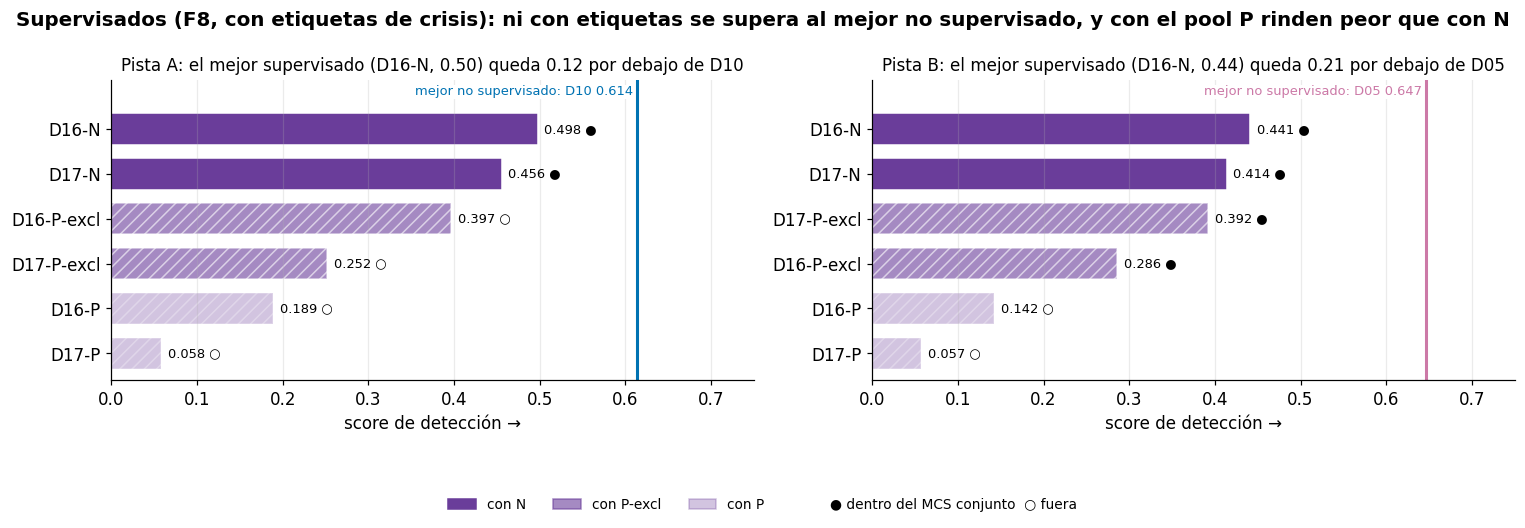

score mejor_no_supervisado  score_mejor  mejora_al_mejor  en_mcs_conjunto    menu
pista id                                                                                           
A     D16-N       0.498                  D10        0.614            False             True       N
      D16-P-excl  0.397                  D10        0.614            False            False  P-excl
      D16-P       0.189                  D10        0.614            False            False       P
      D17-N       0.456                  D10        0.614            False             True       N
      D17-P-excl  0.252                  D10        0.614            False            False  P-excl
      D17-P       0.058                  D10        0.614            False            False       P
B     D16-N       0.441                  D05        0.647            False             True       N
      D16-P-excl  0.286                  D05        0.647            False             True  P-excl
      D16-P       0.142                  D05        0.647            False            False       P
      D17-N       0.414                  D05        0.647            False             True       N
      D17-P-excl  0.392                  D05        0.647            False             True  P-excl
      D17-P       0.057                  D05        0.647            False            False       P

In [14]:
fig = pn.figura_techo(TECHO)
pn.guardar(fig, '08_supervisados')
plt.show()
display(TECHO.set_index(['pista', 'id']).round(3))

## 9. Robustez del criterio y limitaciones

Tres pruebas sobre las métricas ya calculadas (no se reajusta nada) con los detectores del ranking principal:

1. **Parámetros**: β = 0,5 y 2; racha mínima 1 y 5 (recalculada desde los paneles OOS); lift > 1,5; sin filtros de
   persistencia; episodio mínimo 5.
2. **Quitar una crisis cada vez** del recall por evento (*leave-one-crisis-out*).
3. **Azar persistente**: p-valor del score frente a 200 señales de Markov independientes de las crisis con la misma
   tasa de marcado y la misma duración de episodios que el detector. Es más exigente que lift > 1 e informativo: no
   filtra el ranking.

Tarda alrededor de un minuto (el nulo de azar).

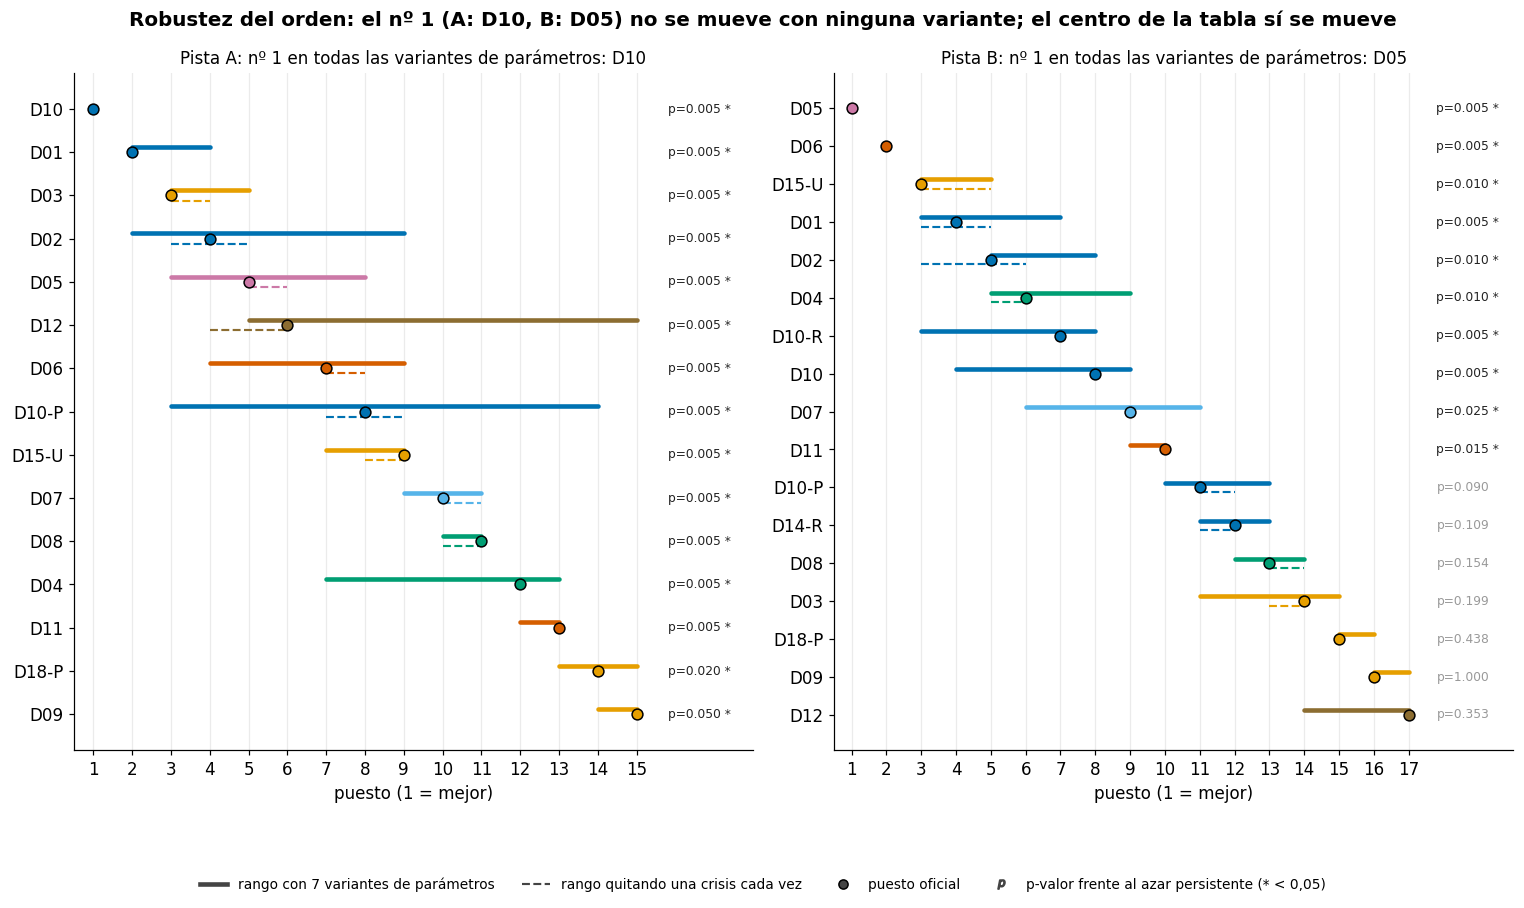

puesto_deteccion  param_min  param_max  loco_min  loco_max  p_valor
pista id                                                                        
A     D10                   1          1          1       1.0       1.0    0.005
      D01                   2          2          4       2.0       2.0    0.005
      D03                   3          3          5       3.0       4.0    0.005
      D02                   4          2          9       3.0       5.0    0.005
      D05                   5          3          8       5.0       6.0    0.005
      D12                   6          5         15       4.0       6.0    0.005
      D06                   7          4          9       7.0       8.0    0.005
      D10-P                 8          3         14       7.0       9.0    0.005
      D15-U                 9          7          9       8.0       9.0    0.005
      D07                  10          9         11      10.0      11.0    0.005
      D08                  11         10         11      10.0      11.0    0.005
      D04                  12          7         13      12.0      12.0    0.005
      D11                  13         12         13      13.0      13.0    0.005
      D18-P                14         13         15      14.0      14.0    0.020
      D09                  15         14         15      15.0      15.0    0.050
B     D05                   1          1          1       1.0       1.0    0.005
      D06                   2          2          2       2.0       2.0    0.005
      D15-U                 3          3          5       3.0       5.0    0.010
      D01                   4          3          7       3.0       5.0    0.005
      D02                   5          5          8       3.0       6.0    0.010
      D04                   6          5          9       5.0       6.0    0.010
      D10-R                 7          3          8       7.0       7.0    0.005
      D10                   8          4          9       8.0       8.0    0.005
      D07                   9          6         11       9.0       9.0    0.025
      D11                  10          9         10      10.0      10.0    0.015
      D10-P                11         10         13      11.0      12.0    0.090
      D14-R                12         11         13      11.0      12.0    0.109
      D08                  13         12         14      13.0      14.0    0.154
      D03                  14         11         15      13.0      14.0    0.199
      D18-P                15         15         16      15.0      15.0    0.438
      D09                  16         16         17      16.0      16.0    1.000
      D12                  17         14         17      17.0      17.0    0.353

Pista A: p ≥ 0,05 frente al azar persistente: ninguno
Pista B: p ≥ 0,05 frente al azar persistente: D10-P, D14-R, D08, D03, D18-P, D09, D12


,spearman,primero_adr003,primero_legacy
pista,,,
A,0.47,D10,D01
B,0.78,D05,D06


nivel_etiqueta  score_deteccion  puesto_deteccion  puesto_legacy  de
pista id                                                                                              
A     AZAR_PERSISTENTE  precision_no_supera_azar            0.297                13           15.0  16
      AZAR_IID                          parpadeo            0.313                14           16.0  16
      SIEMPRE_CRISIS                  degenerado            0.325                15            5.0  16
      SIEMPRE_CALMA                   degenerado            0.000                16            7.0  16
B     AZAR_PERSISTENTE  precision_no_supera_azar            0.240                11           15.0  16
      AZAR_IID                          parpadeo            0.247                14           16.0  16
      SIEMPRE_CRISIS                  degenerado            0.295                15            5.0  16
      SIEMPRE_CALMA                   degenerado            0.000                16            8.0  16

In [15]:
M_PRINCIPAL = pn.metricas_principal(MENUS['menus'], V2)
SENS = pn.sensibilidad(M_PRINCIPAL)
LOCO = pn.loco(M_PRINCIPAL)
NULO = pn.nulo_persistente(R, M_PRINCIPAL, n_sims=200)
ROB = pn.tabla_robustez(R, SENS, LOCO, NULO)
fig = pn.figura_robustez(ROB, SENS)
pn.guardar(fig, '09_robustez')
plt.show()
display(ROB.set_index(['pista', 'id']).round(3))
for t, p in ROB.groupby('pista'):
    print(f"Pista {t}: p ≥ 0,05 frente al azar persistente: {', '.join(p[p.p_valor >= .05].id) or 'ninguno'}")
display(pn.comparacion_legacy(V2).set_index('pista').round(2))
display(pn.baselines_legacy(V2).set_index(['pista', 'id']).round(3))

La última tabla compara, solo para los 12 de v2, el orden ADR-003 con el `rank_medio` de cinco ejes que se usaba
antes (columna legacy de `ranking_v2.csv`): tres de esos ejes premiaban la inactividad, que es lo que el ADR-003
corrige. La tabla de debajo lo muestra con las cuatro líneas base triviales metidas entre los 12 de v2: con el
`rank_medio` la señal «siempre crisis» quedaba en la zona alta (`puesto_legacy`); con el criterio ADR-003 todas
quedan detrás de los detectores elegibles.

**Limitaciones que condicionan la lectura.**

1. **Umbrales convencionales.** Racha mínima, β, lift y filtros de persistencia son elecciones explícitas, no
   estimadas; la figura muestra cuánto mueven el orden.
2. **Pocos eventos** (17 en A, 9 en B): el recall se mueve en saltos de 1/N y el nulo de azar es ancho. Las
   diferencias de score entre detectores consecutivos son pequeñas frente a eso; por eso el MCS deja dentro a la
   mayoría.
3. **Ventanas `[pico, suelo]`**: lo marcado en la recuperación tras el suelo (volatilidad aún alta) cuenta como falsa
   alarma; castiga a los detectores de volatilidad.
4. **Pista B sin la GFC fuera de muestra** y con un entrenamiento inicial dominado por ella: los modelos de estado
   latente quedan anclados a esa crisis.
5. **`label_stability`** vive en [0,5; 1] y depende de la frecuencia de reajuste: solo desempata.
6. **Trampas** (`taper_2013`, `debtceiling_2013`) no entran en el criterio principal; quedan como diagnóstico en las
   métricas.
7. **BIC, silueta y log-verosimilitud** se calculan con ajustes in-sample y features distintas por detector: no son
   comparables y no entran.
8. **Huella.** Las métricas de v2 reproducen las del ADR-003 §4 (tabla de procedencia de §2). Cualquier cambio de
   código o datos invalida la caché y obliga a re-ejecutar el benchmark.

## 10. Conclusiones y qué pasa a las fusiones

Las cinco conclusiones del §0 se sostienen tras la robustez: la cabeza de cada pista no cambia con ningún parámetro
ni al quitar una crisis, y ni el pool (comprimido o no) ni las etiquetas la desplazan. Lo que el notebook **no**
decide es qué detector o combinación alimenta la tool `get_regimen(fecha)`: eso irá en la futura ADR-006 y se
validará en pseudolive.

**Siguiente paso: las fusiones** ([ADR-011](../../docs/decisions/ADR-011-preregistro-fusiones.md)). ¿Mejora alguna
combinación de detectores al mejor detector solo, medida con la misma vara? Los candidatos son exactamente los no
supervisados de este ranking principal (la celda siguiente los lista); los supervisados quedan fuera para no heredar
su ventaja. Se prueban de dos formas:

- **Fusiones fijas** ([15_fusiones_fijas](15_fusiones_fijas.ipynb), que unifica las fusiones anteriores):
  alerta→confirmación, votación k-de-n, OR y AND de parejas. Resultado: **no aportan**.
- **Fusión online** ([16_fusion_online](16_fusion_online.ipynb)): media ponderada de probabilidades con pesos que se
  actualizan según el acierto pasado. Resultado: **indicio** (cumple solo en A) y los pesos no aprenden.

In [16]:
CANDIDATOS = R.groupby('pista')['id'].apply(list)
for t, ids in CANDIDATOS.items():
    print(f'Pista {t}: {len(ids)} candidatos a las fusiones (ADR-011 §2): {", ".join(sorted(ids))}')

Pista A: 15 candidatos a las fusiones (ADR-011 §2): D01, D02, D03, D04, D05, D06, D07, D08, D09, D10, D10-P, D11, D12, D15-U, D18-P
Pista B: 17 candidatos a las fusiones (ADR-011 §2): D01, D02, D03, D04, D05, D06, D07, D08, D09, D10, D10-P, D10-R, D11, D12, D14-R, D15-U, D18-P
